<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS10/JS10-01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Artificial Neural Network (ANN) - Lab 1**

---

---

# **Langkah 1 - Import Library**

---

> Import library dasar Python yang dibutuhkan: `numpy` untuk manipulasi array dan operasi aljabar linier, `matplotlib.pyplot` dan `seaborn` untuk visualisasi grafik, serta `pandas` untuk membaca dan memanipulasi dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

> Library yang diimpor akan digunakan sepanjang alur praktikum: NumPy untuk kalkulasi bobot dan dot product Perceptron, Pandas untuk indexing dataset Iris, dan Matplotlib untuk menampilkan visualisasi error per epoch serta batas keputusan (decision boundary).

---

# **Langkah 2 - Load Data dan Visualisasi**

---

> Muat dataset `iris.csv` tanpa header. Jika file belum tersedia di environment Colab, cell berikut secara otomatis mengunduhnya dari repository resmi UCI Machine Learning. Kemudian visualisasikan sebaran data antara spesies *Iris-setosa* dan *Iris-versicolor* berdasarkan fitur indeks ke-0 (Sepal Length) dan indeks ke-3 (Petal Width).

Dataset iris.csv berhasil diunduh.


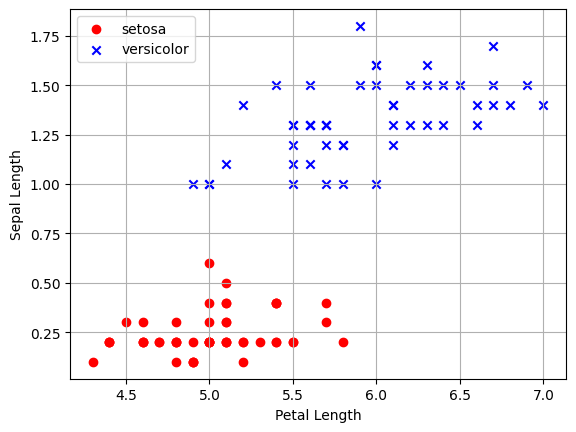

In [2]:
# Pastikan file iris.csv tersedia (otomatis unduh jika belum ada di environment Colab)
import os, urllib.request
if not os.path.exists('iris.csv'):
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
    urllib.request.urlretrieve(url, 'iris.csv')
    print('Dataset iris.csv berhasil diunduh.')

df = pd.read_csv('iris.csv', header=None)
setosa = df[df[4] == 'Iris-setosa']
versicolor = df[df[4] == 'Iris-versicolor']
virginica = df[df[4] == 'Iris-virginica']

a, b = 0, 3
plt.scatter(setosa[a], setosa[b], color='red', marker='o', label='setosa')
plt.scatter(versicolor[a], versicolor[b], color='blue', marker='x', label='versicolor')

plt.xlabel('Petal Length')
plt.ylabel('Sepal Length')
plt.legend(loc='upper left')
plt.grid()
plt.show()

> Dari hasil scatter plot di atas, terlihat jelas bahwa titik-titik data *setosa* (merah, lingkaran) dan *versicolor* (biru, silang) terpisah secara linier (*linearly separable*). Karakteristik ini sangat ideal untuk dimodelkan menggunakan algoritma Perceptron tunggal.

---

# **Langkah 3 - Membuat Kelas Perceptron**

---

> Buat kelas `Perceptron` murni (*from scratch*) dengan komponen:
>
> 1. `__init__(eta, n_iter)`: Mengatur laju pembelajaran (*learning rate*) $\eta$ dan jumlah iterasi (*epochs*).
> 2. `fit(X, y)`: Inisialisasi vektor bobot $w$ (dengan elemen pertama sebagai bias $w_0$) sebesar nol, lalu lakukan pembaruan bobot: $\Delta w = \eta (y - \hat{y})$ pada setiap sampel yang salah diklasifikasikan.
> 3. `net_input(X)`: Menghitung kombinasi linier $z = X \cdot w_{1:} + w_0$.
> 4. `predict(X)`: Fungsi aktivasi tangga (*Heaviside step function*) yang menghasilkan nilai $+1$ jika $z \ge 0$ dan $-1$ jika sebaliknya.

In [3]:
class Perceptron(object):
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

> Kelas `Perceptron` ini mengimplementasikan aturan pembelajaran Rosenblatt. Setiap kali model melakukan kesalahan prediksi, bobot disesuaikan ke arah yang meminimalkan kesalahan tersebut hingga model mencapai konvergensi.

---

# **Langkah 4 - Pilih Data dan Encoding Label**

---

> Ambil 100 data pertama dari dataset (50 sampel Setosa dan 50 sampel Versicolor). Ubah label string `'Iris-setosa'` menjadi $-1$ dan lainnya (Versicolor) menjadi $+1$. Ambil dua fitur pada indeks 0 dan 3 sebagai data masukan $X$.

In [4]:
y = df.iloc[0:100, 4].values # pilih 100 data awal
y = np.where(y == 'Iris-setosa', -1, 1) # ganti coding label
X = df.iloc[0:100, [0, 3]].values # slice data latih

print("Shape X:", X.shape)
print("Shape y:", y.shape)
print("Unique target labels:", np.unique(y))

Shape X: (100, 2)
Shape y: (100,)
Unique target labels: [-1  1]


> Dataset sekarang siap untuk dilatihkan ke model Perceptron dengan 100 baris sampel dan 2 kolom fitur masukan.

---

# **Langkah 5 - Fitting Model**

---

> Inisialisasi objek `Perceptron` dengan learning rate $\eta = 0.1$ dan jumlah iterasi `n_iter = 10`, kemudian lakukan proses pelatihan (*fit*) terhadap data $X$ dan target $y$.

In [5]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

print("Bobot akhir (weights w_):")
print("Bias w0:", ppn.w_[0])
print("Bobot w1, w2:", ppn.w_[1:])
print("Jumlah update kesalahan per epoch:", ppn.errors_)

Bobot akhir (weights w_):
Bias w0: -0.4
Bobot w1, w2: [-0.1   1.12]
Jumlah update kesalahan per epoch: [2, 2, 2, 3, 2, 1, 0, 0, 0, 0]


> Model berhasil dilatih selama 10 epoch. List `ppn.errors_` mencatat frekuensi koreksi bobot di setiap epoch yang menunjukkan proses konvergensi.

---

# **Langkah 6 - Visualisasi Nilai Error Per Epoch**

---

> Plot grafik jumlah kesalahan/pembaruan (*misclassifications/updates*) terhadap nomor epoch untuk memverifikasi apakah model berhasil konvergen ke nilai error 0.

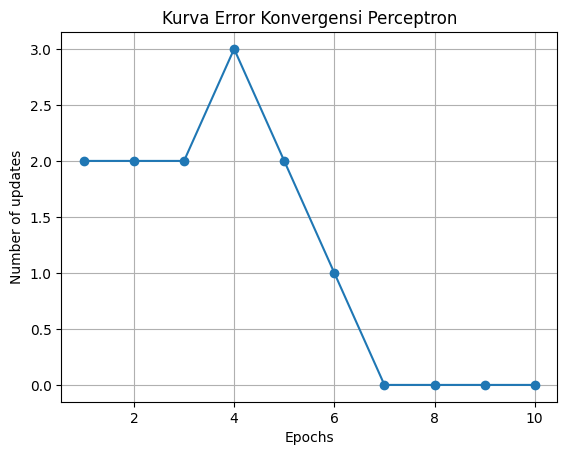

In [6]:
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.title('Kurva Error Konvergensi Perceptron')
plt.grid(True)
plt.show()

> Terlihat bahwa setelah epoch ke-6, jumlah pembaruan bobot turun menjadi 0. Hal ini membuktikan bahwa algoritma Perceptron berhasil menemukan hiperbidang pemisah (*separating hyperplane*) yang sempurna untuk memisahkan kedua kelas bunga iris tersebut.

---

# **Langkah 7 - Visualisasi Decision Boundary**

---

> Buat fungsi `plot_decision_regions` menggunakan kontur warna dan meshgrid untuk memvisualisasikan daerah keputusan (*decision region*) yang dipisahkan oleh garis batas Perceptron.

/tmp/ipykernel_4453/1269319485.py:26: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap(i), marker=markers[i], label=cl)


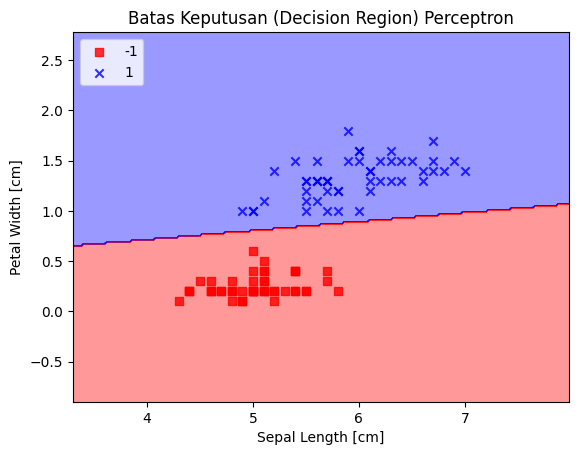

In [7]:
# buat fungsi untuk plot decision region
from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('r', 'b', 'g', 'k', 'grey')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision regions by creating a pair of grid arrays xx1 and xx2 via meshgrid function in Numpy
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution), np.arange(x2_min, x2_max, resolution))

    # use predict method to predict the class labels z of the grid points
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    # draw the contour using matplotlib
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap(i), marker=markers[i], label=cl)

plot_decision_regions(X, y, classifier=ppn)
plt.xlabel('Sepal Length [cm]')
plt.ylabel('Petal Width [cm]')
plt.legend(loc='upper left')
plt.title('Batas Keputusan (Decision Region) Perceptron')
plt.show()

> Plot kontur memperlihatkan garis pembatas linear tegas yang membagi bidang fitur menjadi dua area: area merah untuk kelas $-1$ (Setosa) dan area biru untuk kelas $+1$ (Versicolor). Semua sampel berada di sisi daerah keputusannya masing-masing dengan akurasi 100%.